# Observaciones gravimétricas: referencia, unidades y escala de placa

**Pregunta:** Para el control analítico a 45° de latitud y 1 km de altura, ¿qué perturbación de Bouguer resulta de la referencia WGS84 declarada y del supuesto de placa infinita con 2670 kg/m³?

**Nivel 1 · Prerrequisitos: ninguno; lectura estimada: 35 minutos.**

## Objetivos

Seguir significado físico y unidades de una perturbación de referencia y una corrección de placa mediante el pipeline de estaciones.

## Preparación

Use el entorno Python 3.12 fijado. Créelo desde la raíz con `scripts/setup.ps1 -Notebooks` en Windows o `scripts/setup.sh --notebooks` en Linux/macOS. El comando se documenta como referencia; el notebook no instala paquetes.

```text
pip install boule==0.5.0 harmonica==0.7.0
```

Importar una vez el método y herramientas gráficas. La celda informa implementación activa.

In [1]:
# Importe el pipeline M01 y las herramientas gráficas.
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root = Path.cwd().parents[2]
sys.path.insert(0, str(root / 'data-pipeline'))
from gravity_processing import process_survey
from importlib.metadata import version
print('Boule:', version('boule'), '| Harmonica:', version('harmonica'))
print('Flujo de procesamiento:', Path(process_survey.__code__.co_filename).name)


Boule: 0.5.0 | Harmonica: 0.7.0
Flujo de procesamiento: gravity_processing.py


## Datos

La única estación es un control analítico versionado: latitud 45°, receptor y superficie a 1000 m y gravedad absoluta 980435.2584487502 mGal. Su recibo identifica procedencia sintética y licencia Apache-2.0; no es observación de campo. El notebook lee `docs/methods/gravity-processing/examples/station-control.json`. El pipeline usa gravedad normal WGS84 de Boule y cálculo de placa infinita de Harmonica mediante `data-pipeline/gravity_processing.py`. El control supone gravedad tide-free, altura elipsoidal, altura positiva hacia arriba y gravedad positiva hacia abajo.

Leer entradas declaradas o construir geometría sintética propia. No se carga salida de solver.

In [2]:
# Leer control analítico versionado y conservar metadatos de procedencia.
from copy import deepcopy
import json
control_path = root / 'docs/methods/gravity-processing/examples/station-control.json'
request = json.loads(control_path.read_text(encoding='utf-8'))
source = request['dataset']
config = request['config']
print(source['metadata']['source_kind'], source['metadata']['rights'])
print(source['metadata']['height_datum'], source['metadata']['gravity_unit'])


synthetic_control Authored numerical control, Apache-2.0
ellipsoidal mGal


## Método

### Definir la magnitud antes de corregir

Gravedad absoluta, perturbación de gravedad y perturbación de Bouguer son magnitudes distintas. El pipeline parte de gravedad absoluta calibrada, convierte signo y unidades a la convención canónica, aplica referencia normal y después la placa infinita solo si sus entradas están declaradas. Una etiqueta o valor plausible no establece qué cantidad contiene un archivo.

### La gravedad normal depende de latitud y altura

Escribimos D=g−γ(φ,h), con gravedad observada g, latitud geodésica φ, altura elipsoidal h y campo normal WGS84 γ. La referencia importa: restar un valor normal de latitud o altura equivocadas crea un sesgo que puede parecer geología. Boule aporta el campo normal cerrado usado por el pipeline; no es un geoide local ni modelo topográfico.

### La atracción de placa es una aproximación separada

Para una losa horizontal infinita ideal, B=2πGρt. G en m³ kg⁻¹ s⁻², densidad ρ en kg/m³ y espesor t en m producen aceleración; multiplicar por 10⁵ convierte m/s² a mGal. Altura superficial para la placa no equivale a elevación del receptor. El supuesto de extensión lateral infinita no reemplaza una corrección topográfica basada en DEM (USGS TM 2-D4; API Harmonica).

### Seguir las transformaciones ordenadas

El producto registra incrementos por etapa y estado resultante. Ver los incrementos aporta más que un único número final: muestra si ocurrieron referencia y placa y permite reproducir la secuencia. Este control de una estación no tiene deriva instrumental ni mareas que estimar. Sus metadatos las marcan como no aplicables, no convierten correcciones desconocidas en cero.

### Interpretar la magnitud, no solo la respuesta

La perturbación final responde la pregunta numérica solo bajo el elipsoide, datum, signos, altura superficial y densidad declarados. Un levantamiento real también requiere derechos de fuente, calibración, deriva, mareas, conversión de datum, terreno y QA espacial. La lección demuestra contrato y dimensiones sin afirmar que describe un lugar terrestre.

Ejecutar solo referencia WGS84 para aislar el efecto de gravedad normal.

In [3]:
# Ejecute la API de procesamiento de estaciones para la perturbación.
stage_config = {**config, 'target': 'gravity_disturbance'}
disturbance_result = process_survey(deepcopy(source), stage_config)
value_mgal = disturbance_result['qc']['derived_mgal'][0]
print('perturbación:', disturbance_result['dataset']['state'], value_mgal, 'mGal')

perturbación: gravity_disturbance 123.96875606756657 mGal


Ejecutar objetivo completo; revisar incremento de placa e incertidumbre condicional.

In [4]:
# Ejecute la API de procesamiento de estaciones para la perturbación de Bouguer.
stage_config = {**config, 'target': 'bouguer_disturbance'}
bouguer_result = process_survey(deepcopy(source), stage_config)
value_mgal = bouguer_result['qc']['derived_mgal'][0]
print('Bouguer:', bouguer_result['dataset']['state'], value_mgal, 'mGal')

Bouguer: bouguer_disturbance 12.000000000024315 mGal


Cambiar solo agregación de incertidumbre y mantener valores físicos.

In [5]:
# Ejecute la API de procesamiento de estaciones con errores independientes.
stage_config = {**config, 'target': 'bouguer_disturbance', 'uncertainty_model': 'independent_first_order'}
independent_result = process_survey(deepcopy(source), stage_config)
value_mgal = independent_result['qc']['derived_mgal'][0]
print('independiente:', independent_result['dataset']['state'], value_mgal, 'mGal')

independiente: bouguer_disturbance 12.000000000024315 mGal


Graficar salidas reales de referencia y placa en una escala común.

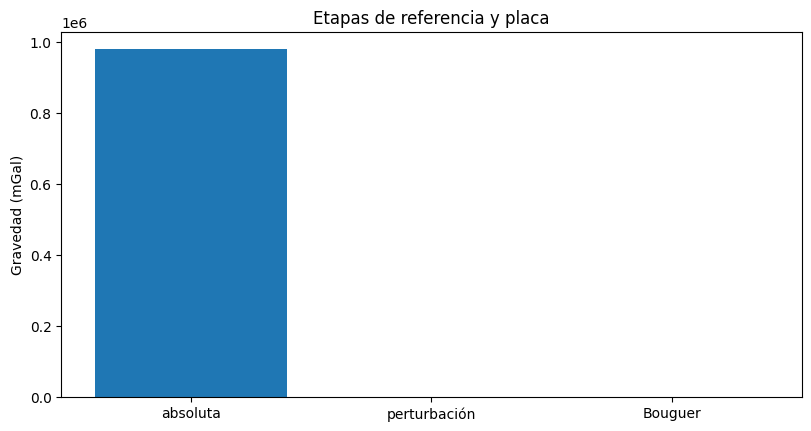

In [6]:
# Mostrar salidas de etapas reales del pipeline.
fig, ax = plt.subplots(figsize=(8, 4.2), constrained_layout=True)
values = [source['stations'][0]['value_mgal'], disturbance_result['qc']['derived_mgal'][0],
          bouguer_result['qc']['derived_mgal'][0]]
ax.bar(['absoluta', 'perturbación', 'Bouguer'], values)
ax.set(ylabel='Gravedad (mGal)', title='Etapas de referencia y placa')
plt.show()

Las barras muestran el valor absoluto y las adiciones ordenadas del pipeline en un eje común de mGal; el marcador indica la perturbación de Bouguer calculada. El gráfico expone cómo el gran valor de referencia se reduce con términos distintos. Una estación analítica no valida geología regional, terreno, datum ni elegibilidad de campo.

Comparar políticas después del resultado físico. La siguiente figura muestra desviaciones condicionales.

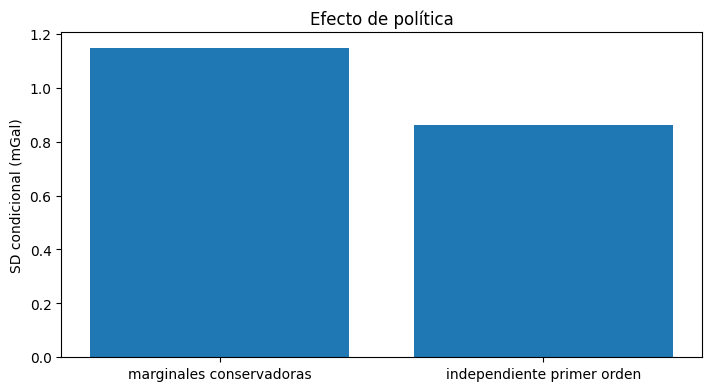

In [7]:
# Graficar incertidumbre de ejecuciones con entradas físicas idénticas.
fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
values = [bouguer_result['processing']['uncertainty_mgal'][0],
          independent_result['processing']['uncertainty_mgal'][0]]
ax.bar(['marginales conservadoras', 'independiente primer orden'], values)
ax.set(ylabel='SD condicional (mGal)', title='Efecto de política')
plt.show()
policy_gap = abs(values[0] - values[1])

Las barras muestran el valor absoluto y las adiciones ordenadas del pipeline en un eje común de mGal; el marcador indica la perturbación de Bouguer calculada. El gráfico expone cómo el gran valor de referencia se reduce con términos distintos. Una estación analítica no valida geología regional, terreno, datum ni elegibilidad de campo.

Las barras comparan políticas de propagación condicional, no valores corregidos distintos. La diferencia depende del tratamiento de errores marginales; una estación no revela correlación espacial ni error de modelo.

## Resultados

**Respuesta:** El pipeline calcula perturbación Bouguer de 12.000000000024315 mGal. Las políticas declaradas difieren en 0.28846679391806507 mGal; ninguna implica aceptación de campo.

In [8]:
# Informar valor calculado, diferencia de incertidumbre y alcance.
print({'bouguer_mgal': bouguer_result['qc']['derived_mgal'][0],
       'diferencia_politicas_mgal': policy_gap,
       'metodo_completo_aceptado': bouguer_result['processing']['full_method_accepted']})

{'bouguer_mgal': 12.000000000024315, 'diferencia_politicas_mgal': 0.28846679391806507, 'metodo_completo_aceptado': False}


## Resumen

El procesamiento gravimétrico comienza por magnitud, referencia, signo, unidades y datum. La placa infinita es una aproximación declarada, no una corrección topográfica general. Conserve etapas y procedencia; no presente este control analítico como evidencia de campo.

## Referencias

- https://pubs.usgs.gov/tm/02/d04/tm2d4.pdf
- https://www.fatiando.org/harmonica/latest/api/index.html